# Practical Lecture Notes: Pandas, Matplotlib & NumPy
## Dataset: Port Operations Master

**Environment:** Jupyter Notebook in VS Code  
**Suggested duration:** 3–4 hours  
**Learning sequence:** Pandas I → Pandas II + Matplotlib → NumPy

### Learning outcomes
By the end, learners should be able to:
- Load, inspect, select, filter and sort operational data with Pandas.
- Group port records and calculate business KPIs using aggregation and transformation.
- Detect and handle missing values and create meaningful charts with Matplotlib.
- Explain NumPy array dimensions, shape, indexing, slicing, reshaping and vectorized calculations.
- Translate port-operations questions into reproducible data-analysis code.

### Business context
A port operations team wants to compare capacity, vessel waiting time, utilization, labor availability, weather disruption and monthly revenue. The goal is to identify bottlenecks and produce a quick operational summary.

> **Data note:** The uploaded file is a 300-row, 14-column CSV. It currently has no missing values. The notebook includes a small, separate demonstration of missing-value handling so learners can practise the workflow without changing the source dataset.

## 0. Setup and load the dataset

### Important modules
- `pandas`: tabular data cleaning and analysis
- `numpy`: numerical arrays and vectorized computation
- `matplotlib.pyplot`: charts
- `pathlib`: reliable file-path handling

**VS Code tip:** Save this notebook in the same folder as `port_operations_master.csv`, or update `DATA_PATH` to the actual location. Select a Python environment with `pandas`, `numpy`, `matplotlib`, and `ipykernel` installed.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Option A: CSV in the same folder as this notebook
DATA_PATH = Path("port_operations_master.csv")

# Option B: if needed, use the full path to your local CSV:
# DATA_PATH = Path(r"C:/path/to/port_operations_master(1).csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH.resolve()}. "
        "Place the CSV beside this notebook or update DATA_PATH."
    )

ports = pd.read_csv(DATA_PATH)
print(f"Rows: {ports.shape[0]:,} | Columns: {ports.shape[1]}")
display(ports.head())

Rows: 300 | Columns: 14


,Port_ID,Port_Name,Country,Port_Type,Port_Capacity_Tons,Avg_Vessel_Wait_Time_Hours,Port_Utilization_Percent,Active_Vessels,Weather_Disruption_Score,Labor_Availability_Percent,Monthly_Port_Revenue_USD,Operational_Status,Port_Manager,Last_Inspection_Date
0,PORT007,Singapore Port,Germany,LNG Terminal,394138,43.17,53.41,130,1.52,72.37,15856508.91,Delayed,Manager_46,2026-04-06
1,PORT020,Hamad Port,China,LNG Terminal,368277,41.57,43.00,15,3.03,73.71,15208535.83,Delayed,Manager_32,2026-06-12
2,PORT015,Nhava Sheva,UAE,LNG Terminal,373412,23.04,77.12,60,2.18,79.54,28601157.62,Normal,Manager_55,2026-03-20
3,PORT011,Khor Fakkan,Iraq,Oil Terminal,481459,19.99,53.03,87,4.59,76.85,6877730.96,Delayed,Manager_96,2026-01-05
4,PORT008,Rotterdam Hub,India,Oil Terminal,238456,14.56,50.44,141,9.30,92.71,45922792.84,Normal,Manager_5,2026-03-01


# Part 1 — Pandas I: Series, DataFrames and basic exploration

## 1.1 Series vs DataFrame

- **Series:** one labelled, one-dimensional column (for example, vessel waiting time).
- **DataFrame:** a two-dimensional labelled table containing rows and columns.
- A DataFrame column is commonly accessed as a Series.

Try changing the column name in the example to explore another variable.

In [2]:
wait_time = ports["Avg_Vessel_Wait_Time_Hours"]  # Series
print(type(wait_time))
display(wait_time.head())

print("DataFrame type:", type(ports))
print("Series shape:", wait_time.shape)
print("DataFrame shape:", ports.shape)

<class 'pandas.Series'>


0    43.17
1    41.57
2    23.04
3    19.99
4    14.56
Name: Avg_Vessel_Wait_Time_Hours, dtype: float64

DataFrame type: <class 'pandas.DataFrame'>
Series shape: (300,)
DataFrame shape: (300, 14)


## 1.2 Inspect the data before analysing it

Useful first-pass methods:
- `head()` / `tail()`: preview rows
- `shape`: row and column counts
- `columns`: column names
- `dtypes`: inferred data types
- `info()`: compact schema and non-null counts
- `describe()`: numerical summary statistics
- `nunique()` and `value_counts()`: categorical summaries

In [3]:
display(ports.head(5))
display(ports.tail(3))
print("Shape:", ports.shape)
print("Columns:", ports.columns.tolist())
print("\nData types:")
display(ports.dtypes.rename("dtype").to_frame())
ports.info()
display(ports.describe().T)

,Port_ID,Port_Name,Country,Port_Type,Port_Capacity_Tons,Avg_Vessel_Wait_Time_Hours,Port_Utilization_Percent,Active_Vessels,Weather_Disruption_Score,Labor_Availability_Percent,Monthly_Port_Revenue_USD,Operational_Status,Port_Manager,Last_Inspection_Date
0,PORT007,Singapore Port,Germany,LNG Terminal,394138,43.17,53.41,130,1.52,72.37,15856508.91,Delayed,Manager_46,2026-04-06
1,PORT020,Hamad Port,China,LNG Terminal,368277,41.57,43.00,15,3.03,73.71,15208535.83,Delayed,Manager_32,2026-06-12
2,PORT015,Nhava Sheva,UAE,LNG Terminal,373412,23.04,77.12,60,2.18,79.54,28601157.62,Normal,Manager_55,2026-03-20
3,PORT011,Khor Fakkan,Iraq,Oil Terminal,481459,19.99,53.03,87,4.59,76.85,6877730.96,Delayed,Manager_96,2026-01-05
4,PORT008,Rotterdam Hub,India,Oil Terminal,238456,14.56,50.44,141,9.30,92.71,45922792.84,Normal,Manager_5,2026-03-01


,Port_ID,Port_Name,Country,Port_Type,Port_Capacity_Tons,Avg_Vessel_Wait_Time_Hours,Port_Utilization_Percent,Active_Vessels,Weather_Disruption_Score,Labor_Availability_Percent,Monthly_Port_Revenue_USD,Operational_Status,Port_Manager,Last_Inspection_Date
297,PORT001,Basra Oil Terminal,Qatar,Container Port,345804,3.57,72.74,61,5.26,76.31,5657599.23,Normal,Manager_22,2026-05-12
298,PORT003,Dammam Port,Oman,LNG Terminal,372648,47.39,51.12,104,6.60,73.16,41510591.63,Critical,Manager_70,2026-01-13
299,PORT018,Jebel Ali,Saudi Arabia,Oil Terminal,240792,7.66,52.28,74,5.23,61.73,3334421.61,Delayed,Manager_21,2026-02-14


Shape: (300, 14)
Columns: ['Port_ID', 'Port_Name', 'Country', 'Port_Type', 'Port_Capacity_Tons', 'Avg_Vessel_Wait_Time_Hours', 'Port_Utilization_Percent', 'Active_Vessels', 'Weather_Disruption_Score', 'Labor_Availability_Percent', 'Monthly_Port_Revenue_USD', 'Operational_Status', 'Port_Manager', 'Last_Inspection_Date']

Data types:


,dtype
Port_ID,str
Port_Name,str
Country,str
Port_Type,str
Port_Capacity_Tons,int64
Avg_Vessel_Wait_Time_Hours,float64
Port_Utilization_Percent,float64
Active_Vessels,int64
Weather_Disruption_Score,float64
Labor_Availability_Percent,float64


<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Port_ID                     300 non-null    str    
 1   Port_Name                   300 non-null    str    
 2   Country                     300 non-null    str    
 3   Port_Type                   300 non-null    str    
 4   Port_Capacity_Tons          300 non-null    int64  
 5   Avg_Vessel_Wait_Time_Hours  300 non-null    float64
 6   Port_Utilization_Percent    300 non-null    float64
 7   Active_Vessels              300 non-null    int64  
 8   Weather_Disruption_Score    300 non-null    float64
 9   Labor_Availability_Percent  300 non-null    float64
 10  Monthly_Port_Revenue_USD    300 non-null    float64
 11  Operational_Status          300 non-null    str    
 12  Port_Manager                300 non-null    str    
 13  Last_Inspection_Date        300 non-null    st

,count,mean,std,min,25%,50%,75%,max
Port_Capacity_Tons,300.0,2.698968e+05,1.306283e+05,51622.00,1.640535e+05,2.596380e+05,3.780460e+05,498058.00
Avg_Vessel_Wait_Time_Hours,300.0,2.523270e+01,1.329342e+01,2.05,1.362000e+01,2.586000e+01,3.670500e+01,47.64
Port_Utilization_Percent,300.0,6.854473e+01,1.616616e+01,40.02,5.415250e+01,6.948000e+01,8.211250e+01,97.74
Active_Vessels,300.0,7.890000e+01,4.378791e+01,6.00,3.975000e+01,8.200000e+01,1.170000e+02,149.00
Weather_Disruption_Score,300.0,5.350567e+00,2.679306e+00,1.00,3.040000e+00,5.105000e+00,7.767500e+00,9.97
Labor_Availability_Percent,300.0,7.503557e+01,1.442626e+01,50.11,6.229000e+01,7.630000e+01,8.711000e+01,99.99
Monthly_Port_Revenue_USD,300.0,2.743508e+07,1.422852e+07,1021696.29,1.525169e+07,2.860203e+07,4.047365e+07,49973846.16


In [4]:
# Inspect categorical columns
for col in ["Country", "Port_Type", "Operational_Status"]:
    print(f"\n{col}: {ports[col].nunique()} unique values")
    display(ports[col].value_counts(dropna=False))


Country: 10 unique values


Country
Iraq            36
Saudi Arabia    36
Oman            35
China           32
Qatar           32
Germany         30
UAE             30
Singapore       26
Kuwait          22
India           21
Name: count, dtype: int64


Port_Type: 3 unique values


Port_Type
LNG Terminal      108
Oil Terminal       97
Container Port     95
Name: count, dtype: int64


Operational_Status: 3 unique values


Operational_Status
Normal      183
Delayed      76
Critical     41
Name: count, dtype: int64

## 1.3 Read data correctly and parse dates

`read_csv()` supports options such as `parse_dates`, `dtype`, `na_values` and `usecols`. Here, convert the inspection date explicitly after loading. Explicit conversion is useful when a date column was imported as text.

In [5]:
ports["Last_Inspection_Date"] = pd.to_datetime(
    ports["Last_Inspection_Date"], errors="coerce"
)
print(ports["Last_Inspection_Date"].dtype)
display(ports[["Port_Name", "Last_Inspection_Date"]].head())

datetime64[us]


,Port_Name,Last_Inspection_Date
0,Singapore Port,2026-04-06
1,Hamad Port,2026-06-12
2,Nhava Sheva,2026-03-20
3,Khor Fakkan,2026-01-05
4,Rotterdam Hub,2026-03-01


## 1.4 Select columns and rows

- `df["column"]`: one Series
- `df[["col_a", "col_b"]]`: a DataFrame with selected columns
- `.loc`: label-based row/column selection
- `.iloc`: integer-position-based selection

**Rule of thumb:** use `.loc` for conditions and labels; use `.iloc` for positions.

In [6]:
# One column vs multiple columns
display(ports["Port_Name"].head())
display(ports[["Port_Name", "Country", "Operational_Status"]].head())

# Label-based selection: rows 0–4 and selected columns
display(ports.loc[0:4, ["Port_Name", "Country", "Port_Capacity_Tons"]])

# Position-based selection: first 5 rows, first 4 columns
display(ports.iloc[:5, :4])

0    Singapore Port
1        Hamad Port
2       Nhava Sheva
3       Khor Fakkan
4     Rotterdam Hub
Name: Port_Name, dtype: str

,Port_Name,Country,Operational_Status
0,Singapore Port,Germany,Delayed
1,Hamad Port,China,Delayed
2,Nhava Sheva,UAE,Normal
3,Khor Fakkan,Iraq,Delayed
4,Rotterdam Hub,India,Normal


,Port_Name,Country,Port_Capacity_Tons
0,Singapore Port,Germany,394138
1,Hamad Port,China,368277
2,Nhava Sheva,UAE,373412
3,Khor Fakkan,Iraq,481459
4,Rotterdam Hub,India,238456


,Port_ID,Port_Name,Country,Port_Type
0,PORT007,Singapore Port,Germany,LNG Terminal
1,PORT020,Hamad Port,China,LNG Terminal
2,PORT015,Nhava Sheva,UAE,LNG Terminal
3,PORT011,Khor Fakkan,Iraq,Oil Terminal
4,PORT008,Rotterdam Hub,India,Oil Terminal


## 1.5 Filtering records

Boolean masks allow us to express business rules directly. The thresholds below are examples for practice, not official operating standards.

In [7]:
# Ports with long average vessel waits
long_wait = ports.loc[
    ports["Avg_Vessel_Wait_Time_Hours"] >= 24,
    ["Port_Name", "Country", "Avg_Vessel_Wait_Time_Hours", "Operational_Status"]
]
display(long_wait.sort_values("Avg_Vessel_Wait_Time_Hours", ascending=False).head(10))

# Multiple conditions: high utilization AND low labor availability
capacity_pressure = ports.loc[
    (ports["Port_Utilization_Percent"] >= 80) &
    (ports["Labor_Availability_Percent"] < 75),
    ["Port_Name", "Port_Utilization_Percent", "Labor_Availability_Percent"]
]
display(capacity_pressure)

# Membership and text filters
display(ports.loc[
    ports["Operational_Status"].isin(["Delayed", "Critical"]),
    ["Port_Name", "Operational_Status", "Avg_Vessel_Wait_Time_Hours"]
].head(10))

display(ports.loc[
    ports["Port_Name"].str.contains("port", case=False, na=False),
    ["Port_Name", "Country"]
].head(10))

,Port_Name,Country,Avg_Vessel_Wait_Time_Hours,Operational_Status
244,Ruwais Port,Kuwait,47.64,Normal
21,Shuaiba Port,Iraq,47.61,Normal
81,Basra Oil Terminal,Germany,47.55,Normal
298,Dammam Port,Oman,47.39,Critical
148,Singapore Port,UAE,47.28,Normal
177,Shanghai Port,Singapore,46.96,Normal
153,Hamad Port,Qatar,46.84,Normal
134,Hamad Port,China,46.51,Normal
111,Salalah Port,UAE,46.37,Normal
106,Shuaiba Port,Kuwait,46.31,Delayed


,Port_Name,Port_Utilization_Percent,Labor_Availability_Percent
14,Qingdao Port,96.44,63.89
23,Salalah Port,94.51,52.24
24,Ruwais Port,82.51,72.53
27,Qingdao Port,82.39,69.49
33,Jebel Ali,96.76,64.84
38,Sohar Port,90.15,50.11
41,Basra Oil Terminal,86.14,52.03
52,Dammam Port,90.25,66.05
54,Nhava Sheva,83.64,70.63
60,Busan Port,93.69,56.94


,Port_Name,Operational_Status,Avg_Vessel_Wait_Time_Hours
0,Singapore Port,Delayed,43.17
1,Hamad Port,Delayed,41.57
3,Khor Fakkan,Delayed,19.99
8,Jebel Ali,Critical,3.63
15,Mundra Port,Delayed,34.00
20,Mundra Port,Critical,43.15
24,Ruwais Port,Delayed,25.74
25,Nhava Sheva,Delayed,43.70
27,Qingdao Port,Delayed,32.46
28,Khor Fakkan,Delayed,27.01


,Port_Name,Country
0,Singapore Port,Germany
1,Hamad Port,China
5,Dammam Port,China
7,Singapore Port,Oman
9,Tianjin Port,UAE
11,Ruwais Port,Iraq
12,Shanghai Port,Germany
13,Hamburg Port,Singapore
14,Qingdao Port,Oman
15,Mundra Port,Saudi Arabia


## 1.6 Sorting and ranking

Sort by one or more columns to find operational outliers. `ascending=False` places the largest values first.

In [8]:
# Top 10 ports by monthly revenue
top_revenue = ports.sort_values("Monthly_Port_Revenue_USD", ascending=False)
display(top_revenue[["Port_Name", "Country", "Monthly_Port_Revenue_USD"]].head(10))

# Sort by status, then by waiting time
display(
    ports.sort_values(
        ["Operational_Status", "Avg_Vessel_Wait_Time_Hours"],
        ascending=[True, False]
    )[["Port_Name", "Operational_Status", "Avg_Vessel_Wait_Time_Hours"]].head(15)
)

,Port_Name,Country,Monthly_Port_Revenue_USD
53,Hamad Port,Oman,49973846.16
192,Singapore Port,UAE,49754087.10
256,Hamburg Port,UAE,49629672.18
143,Rotterdam Hub,China,49520235.79
244,Ruwais Port,Kuwait,49514232.43
157,Tianjin Port,Oman,49101012.87
79,Qingdao Port,China,48754998.76
263,Dammam Port,China,48744239.70
215,Basra Oil Terminal,Oman,48385581.39
179,Khor Fakkan,Kuwait,48153199.95


,Port_Name,Operational_Status,Avg_Vessel_Wait_Time_Hours
298,Dammam Port,Critical,47.39
190,Mundra Port,Critical,45.02
20,Mundra Port,Critical,43.15
29,Fujairah Port,Critical,41.77
226,Ras Laffan,Critical,40.66
66,Ruwais Port,Critical,40.65
168,Qingdao Port,Critical,37.69
102,Busan Port,Critical,37.55
292,Khor Fakkan,Critical,34.45
217,Sohar Port,Critical,32.05


### Checkpoint 1 — Pandas I

1. Show the 10 ports with the lowest labor availability.
2. Filter ports with utilization above 85% and waiting time above 20 hours.
3. Display only port name, port type, capacity and revenue for ports marked `Delayed`.
4. Find how many distinct countries and port types occur in the dataset.

Write your own cells before checking the answer cell below.

In [9]:
# Suggested solutions
display(ports.nsmallest(10, "Labor_Availability_Percent")[
    ["Port_Name", "Labor_Availability_Percent"]
])

display(ports.loc[
    (ports["Port_Utilization_Percent"] > 85) &
    (ports["Avg_Vessel_Wait_Time_Hours"] > 20),
    ["Port_Name", "Port_Utilization_Percent", "Avg_Vessel_Wait_Time_Hours"]
])

display(ports.loc[
    ports["Operational_Status"].eq("Delayed"),
    ["Port_Name", "Port_Type", "Port_Capacity_Tons", "Monthly_Port_Revenue_USD"]
])

print("Countries:", ports["Country"].nunique())
print("Port types:", ports["Port_Type"].nunique())

,Port_Name,Labor_Availability_Percent
38,Sohar Port,50.11
242,Shanghai Port,50.12
216,Basra Oil Terminal,50.16
247,Tianjin Port,50.28
264,Shanghai Port,50.30
109,Jebel Ali,50.34
95,Basra Oil Terminal,50.62
281,Rotterdam Hub,51.10
258,Shuaiba Port,51.22
97,Basra Oil Terminal,51.37


,Port_Name,Port_Utilization_Percent,Avg_Vessel_Wait_Time_Hours
23,Salalah Port,94.51,42.61
30,Busan Port,95.87,35.76
38,Sohar Port,90.15,44.78
42,Ruwais Port,93.28,42.56
44,Fujairah Port,94.57,23.41
45,Fujairah Port,87.96,42.44
52,Dammam Port,90.25,36.81
65,Fujairah Port,90.40,21.88
85,Tianjin Port,95.19,29.34
88,Basra Oil Terminal,87.20,39.79


,Port_Name,Port_Type,Port_Capacity_Tons,Monthly_Port_Revenue_USD
0,Singapore Port,LNG Terminal,394138,15856508.91
1,Hamad Port,LNG Terminal,368277,15208535.83
3,Khor Fakkan,Oil Terminal,481459,6877730.96
15,Mundra Port,Container Port,66725,39367815.23
24,Ruwais Port,Oil Terminal,386326,46613481.23
...,...,...,...,...
287,Ruwais Port,LNG Terminal,306689,11018583.42
288,Salalah Port,Oil Terminal,468641,13510144.75
290,Qingdao Port,Container Port,424999,30096321.56
296,Busan Port,Oil Terminal,319431,23540117.38


Countries: 10
Port types: 3


# Part 2 — Pandas II + Matplotlib

## 2.1 GroupBy: split, apply, combine

`groupby()` separates records into groups, applies an operation to each group and combines the results. It is useful for questions such as:
- Which port types have the longest average waiting time?
- Which countries report the highest average utilization?
- How does operational status relate to revenue or labor availability?

In [10]:
# Summary by operational status
status_summary = (
    ports.groupby("Operational_Status")
    .agg(
        port_count=("Port_ID", "count"),
        avg_wait_hours=("Avg_Vessel_Wait_Time_Hours", "mean"),
        avg_utilization_pct=("Port_Utilization_Percent", "mean"),
        avg_labor_pct=("Labor_Availability_Percent", "mean"),
        total_monthly_revenue_usd=("Monthly_Port_Revenue_USD", "sum")
    )
    .sort_values("avg_wait_hours", ascending=False)
)
display(status_summary.round(2))

,port_count,avg_wait_hours,avg_utilization_pct,avg_labor_pct,total_monthly_revenue_usd
Operational_Status,,,,,
Delayed,76,25.71,67.92,75.14,2.087505e+09
Normal,183,25.51,69.54,75.22,4.852912e+09
Critical,41,23.12,65.26,74.04,1.290108e+09


In [11]:
# Compare port types
type_summary = (
    ports.groupby("Port_Type")
    .agg(
        ports=("Port_ID", "count"),
        avg_capacity_tons=("Port_Capacity_Tons", "mean"),
        median_wait_hours=("Avg_Vessel_Wait_Time_Hours", "median"),
        avg_revenue_usd=("Monthly_Port_Revenue_USD", "mean")
    )
    .sort_values("median_wait_hours", ascending=False)
)
display(type_summary.round(2))

,ports,avg_capacity_tons,median_wait_hours,avg_revenue_usd
Port_Type,,,,
Container Port,95,267621.19,27.75,27418766.99
Oil Terminal,97,256717.86,26.95,27781442.32
LNG Terminal,108,283735.16,23.40,27138351.81


## 2.2 Aggregation vs transformation

- **Aggregation (`agg`)** reduces each group to summary values.
- **Transformation (`transform`)** returns a result aligned to the original rows, making it useful for comparing each port against its group benchmark.

In this example, each row receives its port type's average waiting time and the difference from that benchmark.

In [12]:
ports["Port_Type_Avg_Wait_Hours"] = (
    ports.groupby("Port_Type")["Avg_Vessel_Wait_Time_Hours"].transform("mean")
)
ports["Wait_vs_Type_Avg_Hours"] = (
    ports["Avg_Vessel_Wait_Time_Hours"] - ports["Port_Type_Avg_Wait_Hours"]
)

display(
    ports[[
        "Port_Name", "Port_Type", "Avg_Vessel_Wait_Time_Hours",
        "Port_Type_Avg_Wait_Hours", "Wait_vs_Type_Avg_Hours"
    ]].head(10).round(2)
)

,Port_Name,Port_Type,Avg_Vessel_Wait_Time_Hours,Port_Type_Avg_Wait_Hours,Wait_vs_Type_Avg_Hours
0,Singapore Port,LNG Terminal,43.17,23.91,19.26
1,Hamad Port,LNG Terminal,41.57,23.91,17.66
2,Nhava Sheva,LNG Terminal,23.04,23.91,-0.87
3,Khor Fakkan,Oil Terminal,19.99,25.66,-5.67
4,Rotterdam Hub,Oil Terminal,14.56,25.66,-11.10
5,Dammam Port,Oil Terminal,23.93,25.66,-1.73
6,Jebel Ali,Oil Terminal,4.04,25.66,-21.62
7,Singapore Port,LNG Terminal,41.20,23.91,17.29
8,Jebel Ali,LNG Terminal,3.63,23.91,-20.28
9,Tianjin Port,Container Port,17.14,26.31,-9.17


## 2.3 Create derived columns

Derived variables turn raw data into interpretable metrics. Here we calculate monthly revenue per active vessel and label utilization bands. Avoid dividing by zero in general-purpose pipelines.

In [13]:
ports["Revenue_Per_Active_Vessel_USD"] = (
    ports["Monthly_Port_Revenue_USD"] /
    ports["Active_Vessels"].replace(0, np.nan)
)

ports["Utilization_Band"] = pd.cut(
    ports["Port_Utilization_Percent"],
    bins=[-np.inf, 60, 80, np.inf],
    labels=["Low", "Moderate", "High"],
    right=False
)

display(ports[[
    "Port_Name", "Active_Vessels", "Monthly_Port_Revenue_USD",
    "Revenue_Per_Active_Vessel_USD", "Port_Utilization_Percent", "Utilization_Band"
]].head(10).round(2))

,Port_Name,Active_Vessels,Monthly_Port_Revenue_USD,Revenue_Per_Active_Vessel_USD,Port_Utilization_Percent,Utilization_Band
0,Singapore Port,130,15856508.91,121973.15,53.41,Low
1,Hamad Port,15,15208535.83,1013902.39,43.00,Low
2,Nhava Sheva,60,28601157.62,476685.96,77.12,Moderate
3,Khor Fakkan,87,6877730.96,79054.38,53.03,Low
4,Rotterdam Hub,141,45922792.84,325693.57,50.44,Low
5,Dammam Port,103,36312102.12,352544.68,45.14,Low
6,Jebel Ali,77,20670835.91,268452.41,45.99,Low
7,Singapore Port,119,8772583.08,73719.19,73.91,Moderate
8,Jebel Ali,11,44217616.32,4019783.30,79.92,Moderate
9,Tianjin Port,84,41365126.41,492441.98,63.05,Moderate


## 2.4 Missing values: detect, decide, handle

Start by measuring missingness. Then decide whether to drop, impute, or preserve missing values based on what the field means. Do not automatically fill every column with zero: zero may be a real measurement, not an unknown value.

The uploaded dataset currently contains no missing values. The next cell makes a copy and inserts a few missing values only for teaching.

In [14]:
# Check missingness in the actual dataset
missing_report = (
    ports.isna().sum()
    .rename("missing_count")
    .to_frame()
)
missing_report["missing_percent"] = (
    missing_report["missing_count"] / len(ports) * 100
)
display(missing_report.sort_values("missing_count", ascending=False))

,missing_count,missing_percent
Port_ID,0,0.0
Port_Name,0,0.0
Country,0,0.0
Port_Type,0,0.0
Port_Capacity_Tons,0,0.0
Avg_Vessel_Wait_Time_Hours,0,0.0
Port_Utilization_Percent,0,0.0
Active_Vessels,0,0.0
Weather_Disruption_Score,0,0.0
Labor_Availability_Percent,0,0.0


In [15]:
# Teaching-only copy: intentionally introduce missing values
demo_missing = ports[[
    "Port_Name", "Avg_Vessel_Wait_Time_Hours", "Labor_Availability_Percent"
]].copy()

demo_missing.loc[demo_missing.index[:3], "Avg_Vessel_Wait_Time_Hours"] = np.nan
demo_missing.loc[demo_missing.index[3:5], "Labor_Availability_Percent"] = np.nan

print("Before handling:")
display(demo_missing.head(7))
print(demo_missing.isna().sum())

# Numeric imputation example: use the column median
demo_missing["Avg_Vessel_Wait_Time_Hours"] = demo_missing[
    "Avg_Vessel_Wait_Time_Hours"
].fillna(demo_missing["Avg_Vessel_Wait_Time_Hours"].median())

# Another reasonable option: retain missingness or use a domain-approved method
demo_missing["Labor_Availability_Percent"] = demo_missing[
    "Labor_Availability_Percent"
].fillna(demo_missing["Labor_Availability_Percent"].median())

print("After median imputation:")
display(demo_missing.head(7))
print(demo_missing.isna().sum())

Before handling:


,Port_Name,Avg_Vessel_Wait_Time_Hours,Labor_Availability_Percent
0,Singapore Port,NaN,72.37
1,Hamad Port,NaN,73.71
2,Nhava Sheva,NaN,79.54
3,Khor Fakkan,19.99,NaN
4,Rotterdam Hub,14.56,NaN
5,Dammam Port,23.93,52.47
6,Jebel Ali,4.04,91.67


Port_Name                     0
Avg_Vessel_Wait_Time_Hours    3
Labor_Availability_Percent    2
dtype: int64
After median imputation:


,Port_Name,Avg_Vessel_Wait_Time_Hours,Labor_Availability_Percent
0,Singapore Port,25.74,72.370
1,Hamad Port,25.74,73.710
2,Nhava Sheva,25.74,79.540
3,Khor Fakkan,19.99,76.205
4,Rotterdam Hub,14.56,76.205
5,Dammam Port,23.93,52.470
6,Jebel Ali,4.04,91.670


Port_Name                     0
Avg_Vessel_Wait_Time_Hours    0
Labor_Availability_Percent    0
dtype: int64


## 2.5 Matplotlib visualization

Choose a chart based on the question:
- **Histogram:** distribution of one numeric variable
- **Bar chart:** compare categories
- **Scatter plot:** inspect relationships between two numeric variables
- **Box plot:** compare distributions and potential outliers

Charts should have a title, labelled axes, sensible formatting and a layout that avoids clipped labels.

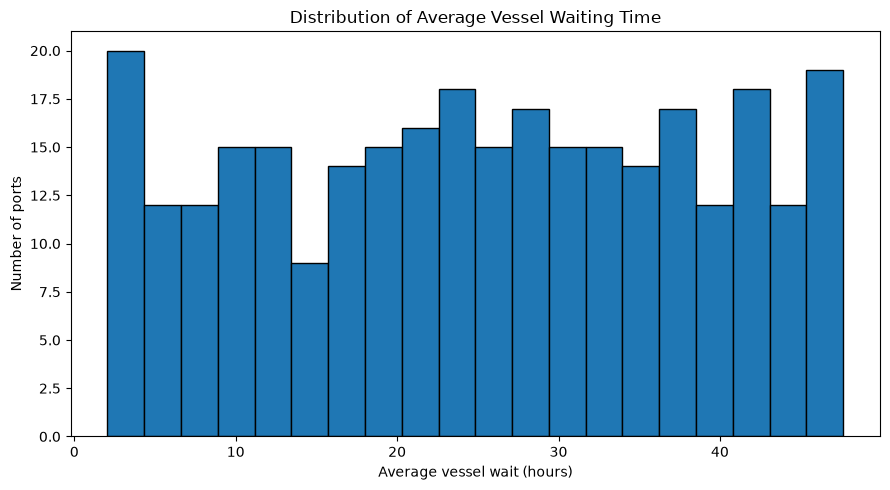

In [16]:
# Histogram: distribution of vessel waiting time
plt.figure(figsize=(9, 5))
plt.hist(ports["Avg_Vessel_Wait_Time_Hours"].dropna(), bins=20, edgecolor="black")
plt.title("Distribution of Average Vessel Waiting Time")
plt.xlabel("Average vessel wait (hours)")
plt.ylabel("Number of ports")
plt.tight_layout()
plt.show()

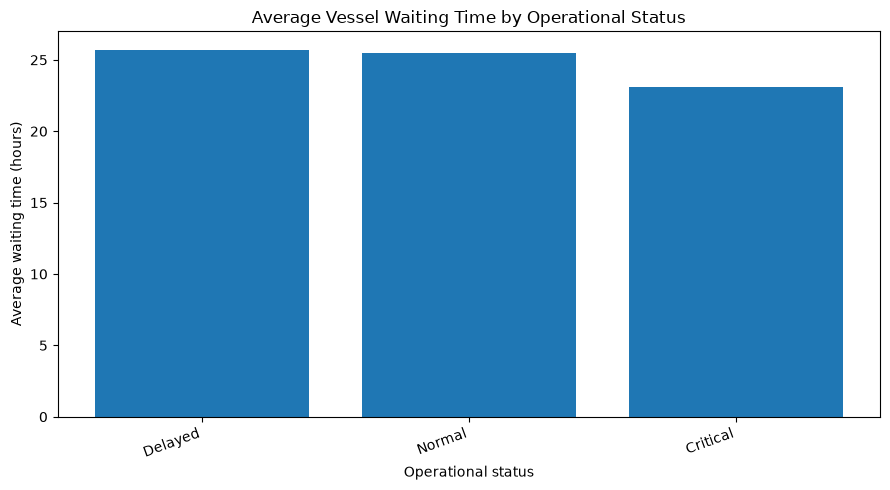

In [17]:
# Bar chart: mean waiting time by operational status
wait_by_status = (
    ports.groupby("Operational_Status")["Avg_Vessel_Wait_Time_Hours"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
plt.bar(wait_by_status.index.astype(str), wait_by_status.values)
plt.title("Average Vessel Waiting Time by Operational Status")
plt.xlabel("Operational status")
plt.ylabel("Average waiting time (hours)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

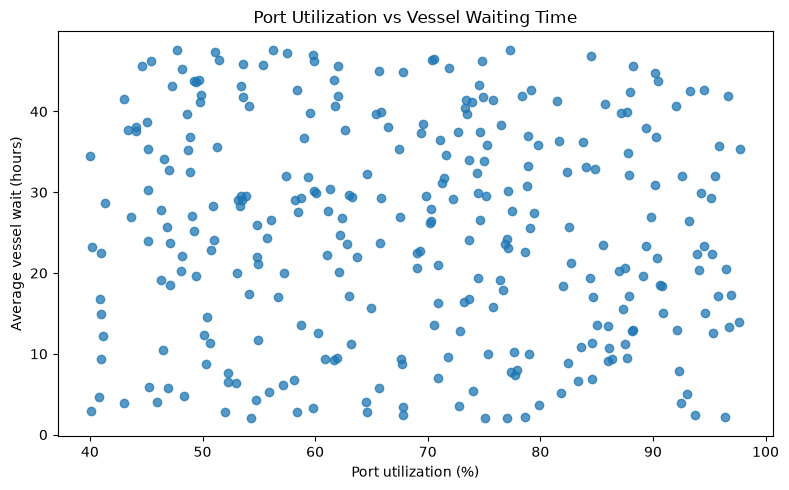

In [18]:
# Scatter plot: utilization vs waiting time
plt.figure(figsize=(8, 5))
plt.scatter(
    ports["Port_Utilization_Percent"],
    ports["Avg_Vessel_Wait_Time_Hours"],
    alpha=0.75
)
plt.title("Port Utilization vs Vessel Waiting Time")
plt.xlabel("Port utilization (%)")
plt.ylabel("Average vessel wait (hours)")
plt.tight_layout()
plt.show()

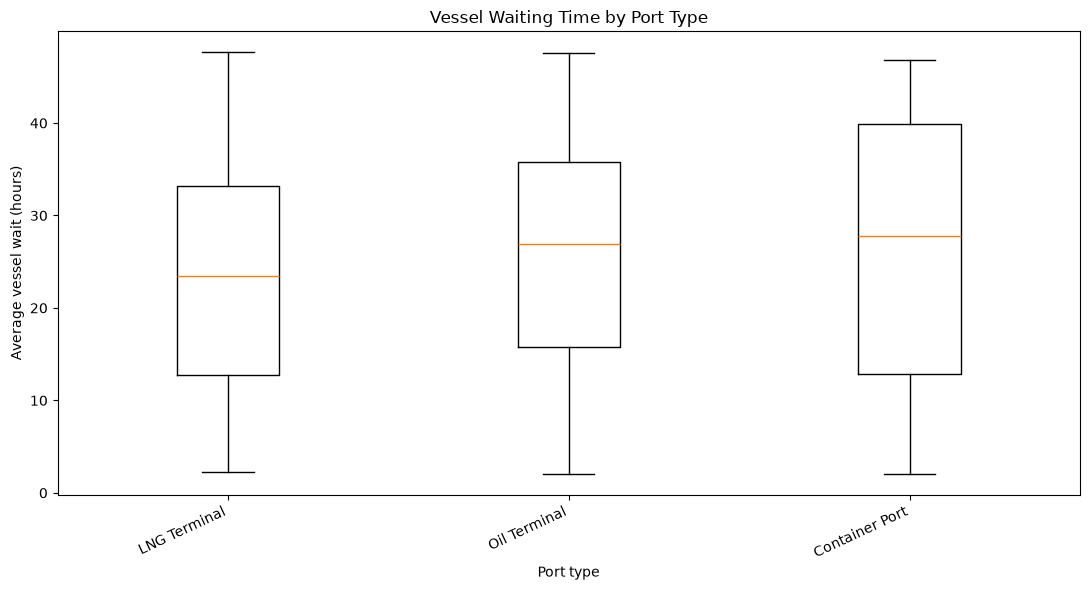

In [19]:
# Box plot: waiting-time distribution by port type
port_types = ports["Port_Type"].dropna().unique()
box_data = [
    ports.loc[ports["Port_Type"] == p, "Avg_Vessel_Wait_Time_Hours"].dropna()
    for p in port_types
]

plt.figure(figsize=(11, 6))
plt.boxplot(box_data, tick_labels=port_types, showfliers=True)
plt.title("Vessel Waiting Time by Port Type")
plt.xlabel("Port type")
plt.ylabel("Average vessel wait (hours)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 2.6 Mini business analysis

Build a small operational watchlist using transparent example rules. The thresholds are for learning and should be validated with port operations stakeholders before being used operationally.

In [20]:
watchlist = ports.loc[
    (ports["Avg_Vessel_Wait_Time_Hours"] >= 24) |
    (ports["Port_Utilization_Percent"] >= 85) |
    (ports["Labor_Availability_Percent"] < 65),
    [
        "Port_Name", "Country", "Operational_Status",
        "Avg_Vessel_Wait_Time_Hours", "Port_Utilization_Percent",
        "Labor_Availability_Percent", "Weather_Disruption_Score"
    ]
].copy()

watchlist["Trigger_Count"] = (
    (watchlist["Avg_Vessel_Wait_Time_Hours"] >= 24).astype(int) +
    (watchlist["Port_Utilization_Percent"] >= 85).astype(int) +
    (watchlist["Labor_Availability_Percent"] < 65).astype(int)
)

display(watchlist.sort_values(
    ["Trigger_Count", "Avg_Vessel_Wait_Time_Hours"],
    ascending=[False, False]
).head(20))

,Port_Name,Country,Operational_Status,Avg_Vessel_Wait_Time_Hours,Port_Utilization_Percent,Labor_Availability_Percent,Weather_Disruption_Score,Trigger_Count
191,Ras Laffan,Germany,Normal,45.58,88.25,51.72,1.62,3
38,Sohar Port,Iraq,Delayed,44.78,90.15,50.11,2.30,3
23,Salalah Port,Oman,Normal,42.61,94.51,52.24,4.11,3
119,Basra Oil Terminal,Oman,Normal,41.93,96.65,55.26,5.56,3
101,Singapore Port,India,Delayed,40.64,92.01,58.28,2.76,3
88,Basra Oil Terminal,Saudi Arabia,Delayed,39.79,87.20,61.31,7.76,3
120,Fujairah Port,Iraq,Normal,34.89,87.74,58.37,6.38,3
243,Mundra Port,Iraq,Delayed,32.13,87.87,52.21,8.90,3
144,Ras Laffan,Oman,Normal,31.97,92.54,57.58,8.41,3
21,Shuaiba Port,Iraq,Normal,47.61,47.70,51.48,6.58,2


### Checkpoint 2 — Pandas II + Matplotlib

1. Calculate average utilization and total monthly revenue by country.
2. Find the port type with the highest median vessel waiting time.
3. Add a column showing each port's revenue as a percentage of total dataset revenue.
4. Plot average labor availability by operational status.
5. Explain why a scatter plot can show association but does not prove causation.

,avg_utilization_pct,total_monthly_revenue_usd,port_count
Country,,,
Iraq,68.33,1.012110e+09,36
Saudi Arabia,67.79,9.990701e+08,36
Oman,68.76,9.601393e+08,35
Qatar,74.02,8.928641e+08,32
China,69.43,8.816791e+08,32
UAE,68.38,8.487499e+08,30
Germany,62.49,7.941214e+08,30
Singapore,71.04,6.643688e+08,26
Kuwait,71.32,5.941534e+08,22


Port type with highest median wait: Container Port


,Port_Name,Revenue_Share_Percent
0,Singapore Port,0.193
1,Hamad Port,0.185
2,Nhava Sheva,0.348
3,Khor Fakkan,0.084
4,Rotterdam Hub,0.558


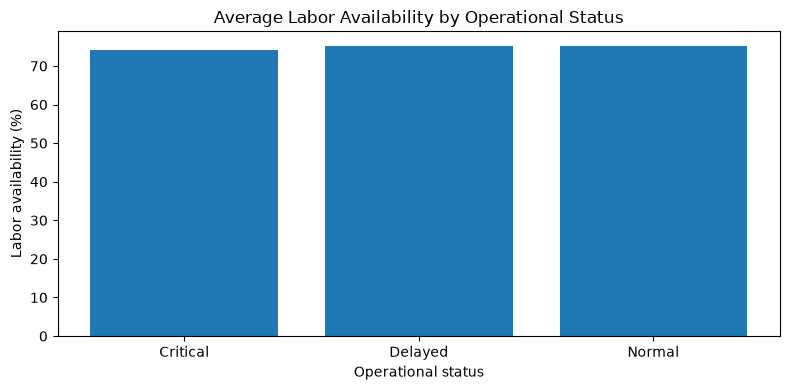

In [21]:
# Suggested solutions
country_summary = ports.groupby("Country").agg(
    avg_utilization_pct=("Port_Utilization_Percent", "mean"),
    total_monthly_revenue_usd=("Monthly_Port_Revenue_USD", "sum"),
    port_count=("Port_ID", "count")
).sort_values("total_monthly_revenue_usd", ascending=False)
display(country_summary.round(2))

print("Port type with highest median wait:",
      ports.groupby("Port_Type")["Avg_Vessel_Wait_Time_Hours"].median().idxmax())

ports["Revenue_Share_Percent"] = (
    ports["Monthly_Port_Revenue_USD"] /
    ports["Monthly_Port_Revenue_USD"].sum() * 100
)
display(ports[["Port_Name", "Revenue_Share_Percent"]].head().round(3))

labor_by_status = ports.groupby("Operational_Status")["Labor_Availability_Percent"].mean()
plt.figure(figsize=(8, 4))
plt.bar(labor_by_status.index.astype(str), labor_by_status.values)
plt.title("Average Labor Availability by Operational Status")
plt.xlabel("Operational status")
plt.ylabel("Labor availability (%)")
plt.tight_layout()
plt.show()

# Part 3 — NumPy: arrays and vectorized operations

Pandas is designed for labelled tabular data; NumPy provides efficient n-dimensional arrays and numerical operations. Pandas numerical columns are often backed by NumPy arrays.

## 3.1 Create arrays and understand dimensions

Key properties:
- `ndim`: number of dimensions
- `shape`: size along each dimension
- `size`: total number of elements
- `dtype`: element data type

A 1-D array can represent a vector, a 2-D array a matrix, and a 3-D array a stack of matrices.

In [22]:
arr_1d = np.array([10, 20, 30, 40])
arr_2d = np.array([[10, 20, 30], [40, 50, 60]])
arr_3d = np.array([
    [[1, 2], [3, 4]],
    [[5, 6], [7, 8]]
])

for name, arr in [("1-D", arr_1d), ("2-D", arr_2d), ("3-D", arr_3d)]:
    print(f"{name}: ndim={arr.ndim}, shape={arr.shape}, size={arr.size}, dtype={arr.dtype}")

1-D: ndim=1, shape=(4,), size=4, dtype=int64
2-D: ndim=2, shape=(2, 3), size=6, dtype=int64
3-D: ndim=3, shape=(2, 2, 2), size=8, dtype=int64


## 3.2 Convert dataset columns to NumPy arrays

Use `.to_numpy()` when numerical computation is easier with arrays. Keep the Pandas index and column labels in mind: NumPy arrays are positional and do not carry DataFrame labels.

In [23]:
wait_array = ports["Avg_Vessel_Wait_Time_Hours"].to_numpy()
util_array = ports["Port_Utilization_Percent"].to_numpy()
revenue_array = ports["Monthly_Port_Revenue_USD"].to_numpy()

print("Wait array shape:", wait_array.shape)
print("First 5 waiting-time values:", wait_array[:5])

Wait array shape: (300,)
First 5 waiting-time values: [43.17 41.57 23.04 19.99 14.56]


## 3.3 Indexing and slicing

Indexing selects an element; slicing selects a range. For a 2-D array, use `[row, column]`. Slices usually return a view into the original array, so be careful when modifying them.

In [24]:
matrix = np.array([
    [100, 200, 300],
    [400, 500, 600],
    [700, 800, 900],
    [1000, 1100, 1200]
])

print("Element at row 2, col 1:", matrix[2, 1])
print("First row:", matrix[0, :])
print("First two rows:", matrix[:2, :])
print("Last column:", matrix[:, -1])
print("Rows 1–3, columns 0–1:")
print(matrix[1:4, 0:2])

Element at row 2, col 1: 800
First row: [100 200 300]
First two rows: [[100 200 300]
 [400 500 600]]
Last column: [ 300  600  900 1200]
Rows 1–3, columns 0–1:
[[ 400  500]
 [ 700  800]
 [1000 1100]]


## 3.4 Reshaping arrays

`reshape()` changes the dimensions without changing the number of elements. The new dimensions must multiply to the same total size. Use `-1` when NumPy should infer one dimension.

In [25]:
values = np.arange(1, 13)
print("Original:", values, values.shape)

matrix_3x4 = values.reshape(3, 4)
print("\n3 x 4:")
print(matrix_3x4)

matrix_2x6 = values.reshape(2, -1)
print("\n2 x inferred columns:")
print(matrix_2x6)

# Flatten a multi-dimensional array
print("\nFlattened:", matrix_3x4.ravel())

Original: [ 1  2  3  4  5  6  7  8  9 10 11 12] (12,)

3 x 4:
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]

2 x inferred columns:
[[ 1  2  3  4  5  6]
 [ 7  8  9 10 11 12]]

Flattened: [ 1  2  3  4  5  6  7  8  9 10 11 12]


## 3.5 Vectorized operations and broadcasting

Vectorization applies operations to whole arrays without writing Python loops for each element. Broadcasting lets compatible shapes interact, such as subtracting a scalar from every value in an array.

In [26]:
# Convert waiting hours to minutes and calculate an illustrative 10% reduction scenario
wait_minutes = wait_array * 60
target_wait_hours = wait_array * 0.90

print("First 5 wait times (minutes):", wait_minutes[:5].round(1))
print("First 5 target wait times (hours):", target_wait_hours[:5].round(2))

# Broadcasting: center each value around the mean
centered_wait = wait_array - np.nanmean(wait_array)
print("Mean of centered values (approximately 0):", np.nanmean(centered_wait).round(10))

First 5 wait times (minutes): [2590.2 2494.2 1382.4 1199.4  873.6]
First 5 target wait times (hours): [38.85 37.41 20.74 17.99 13.1 ]
Mean of centered values (approximately 0): -0.0


In [27]:
# Compare a vectorized expression with a Python loop
sample = wait_array[:10]

loop_result = []
for x in sample:
    loop_result.append(x * 60)

vectorized_result = sample * 60

print("Loop:", np.round(loop_result, 2))
print("Vectorized:", np.round(vectorized_result, 2))
print("Same result:", np.allclose(loop_result, vectorized_result))

Loop: [2590.2 2494.2 1382.4 1199.4  873.6 1435.8  242.4 2472.   217.8 1028.4]
Vectorized: [2590.2 2494.2 1382.4 1199.4  873.6 1435.8  242.4 2472.   217.8 1028.4]
Same result: True


## 3.6 Boolean masks and numerical summaries

NumPy masks can select values based on conditions. `np.where()` can create values conditionally. Use `nan`-aware summary functions when arrays may contain missing numerical values.

In [28]:
high_wait_mask = wait_array >= 24
print("Ports with wait >= 24 hours:", high_wait_mask.sum())
print("Mean wait:", np.nanmean(wait_array).round(2))
print("Median wait:", np.nanmedian(wait_array).round(2))
print("Minimum / maximum:", np.nanmin(wait_array), "/", np.nanmax(wait_array))

wait_category = np.where(wait_array >= 24, "Long wait", "Below 24 hours")
print("First 10 labels:", wait_category[:10])

Ports with wait >= 24 hours: 159
Mean wait: 25.23
Median wait: 25.86
Minimum / maximum: 2.05 / 47.64
First 10 labels: ['Long wait' 'Long wait' 'Below 24 hours' 'Below 24 hours'
 'Below 24 hours' 'Below 24 hours' 'Below 24 hours' 'Long wait'
 'Below 24 hours' 'Below 24 hours']


## 3.7 NumPy calculations across multiple columns

Stack selected numeric columns into a 2-D array. Columns should be interpreted carefully because they have different units. Standardization below is a mathematical demonstration, not a business score.

In [29]:
metrics = ports[[
    "Avg_Vessel_Wait_Time_Hours",
    "Port_Utilization_Percent",
    "Labor_Availability_Percent"
]].to_numpy(dtype=float)

print("Metrics matrix shape:", metrics.shape)

column_means = np.nanmean(metrics, axis=0)
column_stds = np.nanstd(metrics, axis=0)

# Avoid division by zero if a column has zero variance
safe_stds = np.where(column_stds == 0, 1, column_stds)
standardized_metrics = (metrics - column_means) / safe_stds

print("Column means:", column_means.round(2))
print("Column standard deviations:", column_stds.round(2))
print("First 5 standardized rows:")
print(standardized_metrics[:5].round(2))

Metrics matrix shape: (300, 3)
Column means: [25.23 68.54 75.04]
Column standard deviations: [13.27 16.14 14.4 ]
First 5 standardized rows:
[[ 1.35 -0.94 -0.19]
 [ 1.23 -1.58 -0.09]
 [-0.17  0.53  0.31]
 [-0.4  -0.96  0.13]
 [-0.8  -1.12  1.23]]


### Checkpoint 3 — NumPy

1. Create a NumPy array from port capacity and print its shape, dimensions and data type.
2. Extract the first 10 values and the last 5 values.
3. Reshape the first 12 capacities into a 3 × 4 matrix.
4. Calculate the difference between each port's waiting time and the overall mean waiting time.
5. Use a boolean mask to count ports with utilization greater than 80%.
6. Explain why mixing revenue (USD) and utilization (%) directly in one unscaled formula can be misleading.

In [30]:
# Suggested solutions
capacity_array = ports["Port_Capacity_Tons"].to_numpy()
print("shape:", capacity_array.shape, "ndim:", capacity_array.ndim, "dtype:", capacity_array.dtype)
print("First 10:", capacity_array[:10])
print("Last 5:", capacity_array[-5:])
print("3 x 4 matrix:")
print(capacity_array[:12].reshape(3, 4))

wait_deviation = wait_array - np.nanmean(wait_array)
print("First 10 wait deviations:", wait_deviation[:10].round(2))

util_mask = util_array > 80
print("Ports above 80% utilization:", int(util_mask.sum()))

shape: (300,) ndim: 1 dtype: int64
First 10: [394138 368277 373412 481459 238456  81653 207729 483168 465396 278504]
Last 5: [104028 319431 345804 372648 240792]
3 x 4 matrix:
[[394138 368277 373412 481459]
 [238456  81653 207729 483168]
 [465396 278504 171829 178377]]
First 10 wait deviations: [ 17.94  16.34  -2.19  -5.24 -10.67  -1.3  -21.19  15.97 -21.6   -8.09]
Ports above 80% utilization: 79


# Final mini-project — Port Operations Performance Brief

## Task
Prepare a short, evidence-based brief for an operations manager using the dataset.

### Required outputs
1. A table of the five ports with the longest vessel waiting time.
2. A group summary by operational status containing count, average wait, average utilization and total revenue.
3. One chart comparing average waiting time by port type.
4. One derived metric of your choice, with a clear formula.
5. Three findings supported by calculated values, plus two limitations or caveats.

### Suggested workflow
1. Inspect the data and validate types.
2. Filter and sort to locate potential bottlenecks.
3. Aggregate by status or port type.
4. Visualize the most important comparison.
5. Write conclusions without claiming causation from simple correlations.

### Submission checklist
- [ ] Notebook cells run from top to bottom without errors.
- [ ] Chart titles and axes are labelled.
- [ ] Derived metrics have named columns and documented formulas.
- [ ] Missing-value decisions are explained.
- [ ] Findings cite computed numbers, not assumptions.
- [ ] Source CSV is unchanged.

,Port_Name,Country,Operational_Status,Avg_Vessel_Wait_Time_Hours
244,Ruwais Port,Kuwait,Normal,47.64
21,Shuaiba Port,Iraq,Normal,47.61
81,Basra Oil Terminal,Germany,Normal,47.55
298,Dammam Port,Oman,Critical,47.39
148,Singapore Port,UAE,Normal,47.28


,port_count,avg_wait_hours,avg_utilization_pct,total_revenue_usd
Operational_Status,,,,
Critical,41,23.12,65.26,1.290108e+09
Delayed,76,25.71,67.92,2.087505e+09
Normal,183,25.51,69.54,4.852912e+09


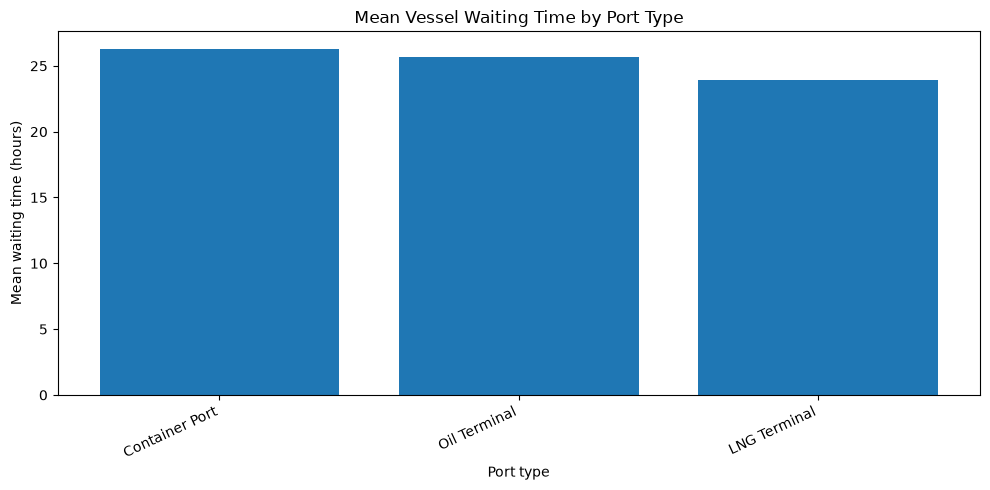

In [31]:
# Starter cell for the final brief
top_waiting_ports = ports.nlargest(
    5, "Avg_Vessel_Wait_Time_Hours"
)[["Port_Name", "Country", "Operational_Status", "Avg_Vessel_Wait_Time_Hours"]]
display(top_waiting_ports)

status_brief = ports.groupby("Operational_Status").agg(
    port_count=("Port_ID", "count"),
    avg_wait_hours=("Avg_Vessel_Wait_Time_Hours", "mean"),
    avg_utilization_pct=("Port_Utilization_Percent", "mean"),
    total_revenue_usd=("Monthly_Port_Revenue_USD", "sum")
).round(2)
display(status_brief)

wait_by_type = ports.groupby("Port_Type")["Avg_Vessel_Wait_Time_Hours"].mean().sort_values(ascending=False)
plt.figure(figsize=(10, 5))
plt.bar(wait_by_type.index.astype(str), wait_by_type.values)
plt.title("Mean Vessel Waiting Time by Port Type")
plt.xlabel("Port type")
plt.ylabel("Mean waiting time (hours)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()